# 01: EDA and data audit (HKUST primary data)

This notebook is built up task by task (Stage 1 in `PLAN.md`). Reusable code is in `src/`; the cells here stay short and simple.

## 1. Setup

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
from src import inventory

## 2. Station inventory

One row per site-level power file. File facts (resolution, dates, rows) come from the CSVs. Rated power, tilt, azimuth and location come from the `.ttl` metadata, matched by station name (all 60 match; one name, *Indoor Sports Centre*, needed a manual fix).

In [2]:
inv = inventory.build_inventory()
inv.shape

(60, 18)

In [3]:
inv.head()

,station,has_optimizer,resolution_min,start,end,n_rows,n_duplicate_timestamps,n_inverter_files,ttl_name,latitude,longitude,altitude_m,connection_date,rated_unit,rated_value,azimuth_raw,tilt_raw,contractor
0,Indoor Sports Centre,True,15.0,2021-12-02,2023-12-31 23:45:00,72960,0,1,Indoor_Sport_Center,22.28,114.17,3.0,2021-12-01T00:00:00,KW,33.3,0/180deg,10deg,SolarEdge
1,LSK North,True,15.0,2021-06-01,2023-12-31 23:45:00,90624,0,1,LSK_North,22.33,114.18,142.0,2021-04-30T00:00:00,KW,55.0,10/-153deg,10deg,SolarEdge
2,LSK South,True,15.0,2021-06-01,2023-12-31 23:45:00,90624,0,1,LSK_South,22.33,114.18,152.0,2021-04-30T00:00:00,KW,25.0,0deg,0deg,SolarEdge
3,Library,True,15.0,2022-06-01,2023-12-31 23:45:00,55584,0,3,Library,22.28,114.17,87.0,2022-05-31 00:00:00,KW,170.2,Mixed,10deg,SolarEdge
4,S H Ho Sports Hall,True,15.0,2021-11-01,2023-12-31 23:45:00,75936,0,2,S_H_Ho_Sports_Hall,22.28,114.17,96.0,2021-10-02 00:00:00,KW,42.0,0deg,0deg,SolarEdge


### Checks on the join

In [4]:
print('files without .ttl match:', inv['ttl_name'].isna().sum())
print('rated power units:', inv['rated_unit'].unique())
print('inverter files:', inv['n_inverter_files'].sum())

files without .ttl match: 0
rated power units: <StringArray>
['KW']
Length: 1, dtype: str
inverter files: 44


In [5]:
inv.groupby('has_optimizer')[['resolution_min']].agg(['count', 'min', 'max'])

resolution_min            
                       count   min   max
has_optimizer                           
False                     23  60.0  60.0
True                      37  15.0  15.0

### Stations with problems to note

In [6]:
inv[inv['n_duplicate_timestamps'] > 0][['station', 'n_rows', 'n_duplicate_timestamps']]

,station,n_rows,n_duplicate_timestamps
39,SQ Apartment37-48 Flexible PV,21088,432
46,SQ14,24429,586
58,Zone L1 (Station 1),33958,10099
59,Zone L1(Station 2),25929,2074


In [7]:
inv[inv['start'] >= '2023-01-01'][['station', 'has_optimizer', 'start']]

,station,has_optimizer,start
9,SQ Block P,True,2023-07-01
17,Shaw Auditorium,True,2023-08-01
24,UG Hall8,True,2023-03-02
25,UG Hall9,True,2023-02-11


In [8]:
inv[inv['end'] >= '2024-01-01'][['station', 'end']]

,station,end
58,Zone L1 (Station 1),2024-01-01 03:00:00


### Save the table

In [9]:
inv.to_csv('../results/tables/01_station_inventory.csv', index=False)

## 3. Units and timezone

### 3.1 Power (W) vs generation (kWh)

If `power(W)` is a mean over the step, then `generation(kWh)` should equal power x step length / 1000. We test that for both station types.

In [10]:
from src import data_io
files = data_io.list_station_files()
hourly = files[~files['has_optimizer']]
quarter = files[files['has_optimizer']]

**Hourly stations (23):** share of rows where kWh x 1000 equals W (within 1 W), among rows that are not missing.

In [11]:
shares = []
for path in hourly['path']:
    x = data_io.read_station_power(path).dropna()
    diff = (x['generation(kWh)'] * 1000 - x['power(W)']).abs()
    shares.append((diff <= 1).mean())

print('lowest share of matching rows:', min(shares))

lowest share of matching rows: 1.0


**15-min stations (37):** total kWh divided by (sum of W x 0.25 h / 1000). A value of 1.00 would mean exact agreement.

In [12]:
ratios = []
for path in quarter['path']:
    x = data_io.read_station_power(path)
    x = x[~x.index.duplicated()]
    expected = x['power(W)'].sum() * 0.25 / 1000
    ratios.append(x['generation(kWh)'].sum() / expected)

print('min:', round(min(ratios), 3), ' max:', round(max(ratios), 3))

min: 1.028  max: 1.033


### 3.2 Irradiance (W/m2)

In [13]:
irr = data_io.read_weather('irradiance')['Irradiance (W/m2)']
irr.describe().round(1)

count    1567792.0
mean         150.6
std          253.5
min            0.0
25%            4.9
50%           23.7
75%          177.9
max         3608.6
Name: Irradiance (W/m2), dtype: float64

In [14]:
print('values above 1500 W/m2:', (irr > 1500).sum(), 'of', len(irr))
night = irr[irr.index.hour <= 4]
print('night (00-04h) median:', round(night.median(), 1), ' 95th percentile:', round(night.quantile(0.95), 1))

values above 1500 W/m2: 739 of 1567792
night (00-04h) median: 5.4  95th percentile: 31.8


### 3.3 Timezone

The timestamps carry no timezone. If they are Hong Kong local time (UTC+8), irradiance should peak near solar noon. At longitude 114.17 E solar noon is about 12:23 on the clock (12 h + (120 - 114.17) / 15 h), moving by up to about 15 min over the year (equation of time). If the clock were UTC, the peak would be near 04:20.

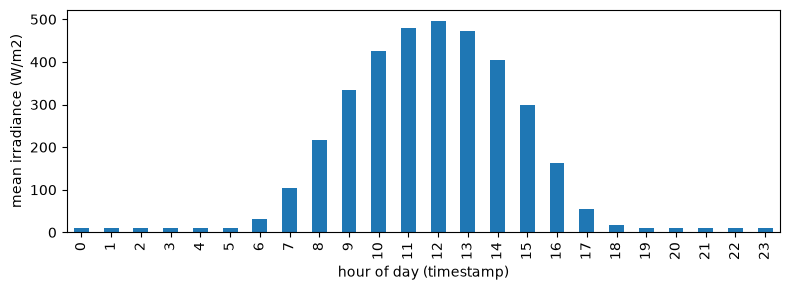

In [15]:
import matplotlib.pyplot as plt

mean_by_hour = irr.groupby(irr.index.hour).mean()
mean_by_hour.plot(kind='bar', figsize=(8, 3))
plt.xlabel('hour of day (timestamp)')
plt.ylabel('mean irradiance (W/m2)')
plt.tight_layout()
plt.savefig('../results/figures/01_irradiance_by_hour.png', dpi=120)
plt.show()

Daily centre of mass of irradiance (hour of day), median per month, on days with almost no missing minutes:

In [16]:
clock_hour = irr.index.hour + irr.index.minute / 60
day = irr.index.normalize()
table = pd.DataFrame({'irr': irr.values, 'weighted': irr.values * clock_hour, 'day': day})
daily = table.groupby('day').agg(total=('irr', 'sum'), weighted=('weighted', 'sum'), minutes=('irr', 'size'))
daily = daily[daily['minutes'] >= 1400]
daily['centre_hour'] = daily['weighted'] / daily['total']
daily.groupby(daily.index.month)['centre_hour'].median().round(2)

day
1     12.42
2     12.55
3     12.55
4     12.29
5     12.21
6     12.10
7     12.14
8     12.13
9     12.17
10    12.06
11    12.02
12    12.14
Name: centre_hour, dtype: float64

### Findings

- **Hourly stations:** `generation(kWh)` x 1000 equals `power(W)` wherever values exist (the other rows are missing values), so `power` is the mean power over the hour and `generation` is the energy of that hour.
- **15-min stations:** `generation(kWh)` summed over a station is 2.8-3.3 % above `power(W)` x 0.25 h / 1000, and the per-row ratio varies (5th-95th percentile about 0.21-0.32 instead of 0.25). So `power(W)` is close to, but not exactly, the mean power of the 15-min step. Which one is the model target is decided in Stage 2; power in W is the planned target.
- **Irradiance** is in W/m2 and never negative. A few values exceed 1500 W/m2 (max 3608, outliers). There is a small non-zero night level (median about 5 W/m2), which is a sensor offset to handle in preprocessing.
- **Timezone:** the irradiance centre of mass is between about 12.0 and 12.6 h in every month, close to the expected solar noon (about 12.1-12.6 h through the year). The timestamps are therefore local Hong Kong time (UTC+8, no daylight saving). A summer dip of up to about 20 min is plausible from afternoon clouds; we did not investigate it.

## 4. Timestamp convention and alignment

Question: does a timestamp label the **start** or the **end** of its interval (15 min or 1 h)?

Method: irradiance is measured every minute. For a station value at time `t`, we take the mean irradiance over a window of the same length (15 or 60 min) that ends at `t + k` minutes, and compute the correlation with the station power. The best `k` shows which part of time the value really describes:

- window ends at `t` (`k = 0`): the value covers the interval **before** `t` (label = interval end)
- window ends at `t + 15` for 15-min data (`k = 15`): the value covers the interval **after** `t` (label = interval start)

Only daytime rows are used (mean irradiance above 50 W/m2).

### 4.1 Setup: irradiance on a full 1-minute grid

In [17]:
irr = data_io.read_weather('irradiance')['Irradiance (W/m2)']
irr = irr[~irr.index.duplicated()]
minute_grid = pd.date_range('2021-01-01', '2023-12-31 23:59', freq='1min')
irr = irr.reindex(minute_grid)
print('missing minutes:', irr.isna().sum())
print('weather timestamps with seconds:', (irr.dropna().index.second != 0).sum())

missing minutes: 9008
weather timestamps with seconds: 0


In [18]:
mean15 = irr.rolling(15, min_periods=15).mean()
mean60 = irr.rolling(60, min_periods=60).mean()

### 4.2 Do the timestamps sit on the same grid?

In [19]:
minutes_15 = []
for path in quarter['path']:
    x = data_io.read_station_power(path)
    minutes_15.append(set(x.index.minute))
print('minute values in 15-min files:', sorted(set.union(*minutes_15)))

minutes_60 = []
for path in hourly['path']:
    x = data_io.read_station_power(path)
    minutes_60.append(set(x.index.minute))
print('minute values in hourly files:', sorted(set.union(*minutes_60)))

minute values in 15-min files: [0, 15, 30, 45]


minute values in hourly files: [0]


### 4.3 Helper and rated power (used to drop impossible power values)

In [20]:
def corr_at_shift(series, window_mean, k):
    shifted = window_mean.shift(-k).reindex(series.index)
    ok = series.notna() & shifted.notna() & (shifted > 50)
    return series[ok].corr(shifted[ok])

rated = pd.read_csv('../results/tables/01_station_inventory.csv').set_index('station')['rated_value']

### 4.4 15-min stations (37): power and generation

In [21]:
shifts_15 = list(range(0, 31, 3))
rows_power = []
rows_gen = []
for name, path in zip(quarter['station'], quarter['path']):
    x = data_io.read_station_power(path)
    x = x[~x.index.duplicated()]
    power = x['power(W)'].clip(lower=0, upper=1.2 * rated[name] * 1000)
    gen = x['generation(kWh)'].clip(lower=0)
    rows_power.append([corr_at_shift(power, mean15, k) for k in shifts_15])
    rows_gen.append([corr_at_shift(gen, mean15, k) for k in shifts_15])

In [22]:
power_15 = pd.DataFrame(rows_power, columns=shifts_15)
gen_15 = pd.DataFrame(rows_gen, columns=shifts_15)
table_15 = pd.DataFrame({'power_W': power_15.mean(), 'generation_kWh': gen_15.mean()}).round(4)
table_15.index.name = 'k_minutes'
table_15

,power_W,generation_kWh
k_minutes,,
0,0.8090,0.8271
3,0.8195,0.8378
6,0.8303,0.8476
9,0.8404,0.8555
12,0.8479,0.8593
15,0.8510,0.8583
18,0.8485,0.8523
21,0.8421,0.8436
24,0.8332,0.8335


In [23]:
print('best k per station (power):')
print(power_15.idxmax(axis=1).value_counts().sort_index())

best k per station (power):
12     8
15    19
18    10
Name: count, dtype: int64


### 4.5 Hourly stations (23)

In [24]:
shifts_60 = list(range(-60, 31, 10))
rows_hour = []
for name, path in zip(hourly['station'], hourly['path']):
    x = data_io.read_station_power(path)
    x = x[~x.index.duplicated()]
    power = x['power(W)'].clip(lower=0, upper=1.2 * rated[name] * 1000)
    rows_hour.append([corr_at_shift(power, mean60, k) for k in shifts_60])

In [25]:
power_60 = pd.DataFrame(rows_hour, columns=shifts_60)
table_60 = power_60.mean().round(4).rename('power_W').to_frame()
table_60.index.name = 'k_minutes'
table_60

,power_W
k_minutes,
-60,0.7283
-50,0.7606
-40,0.7893
-30,0.8133
-20,0.8316
-10,0.8432
0,0.8450
10,0.8350
20,0.8159


In [26]:
print('best k per station:')
print(power_60.idxmax(axis=1).value_counts().sort_index())

best k per station:
-10    10
 0     11
 10     1
 20     1
Name: count, dtype: int64


### 4.6 Is it the same in every year? (15-min stations, power)

In [27]:
shifts_year = [0, 9, 15, 21]
result_year = {}
for year in [2021, 2022, 2023]:
    rows = []
    for name, path in zip(quarter['station'], quarter['path']):
        x = data_io.read_station_power(path)
        x = x[~x.index.duplicated()]
        power = x['power(W)'].clip(lower=0, upper=1.2 * rated[name] * 1000)
        power = power[power.index.year == year]
        rows.append([corr_at_shift(power, mean15, k) for k in shifts_year])
    result_year[year] = pd.DataFrame(rows, columns=shifts_year).mean()
pd.DataFrame(result_year).round(4)

,2021,2022,2023
0,0.8484,0.8817,0.8756
9,0.8890,0.9134,0.9078
15,0.9029,0.9226,0.9192
21,0.8917,0.9138,0.9098


### 4.7 Save the table and a figure

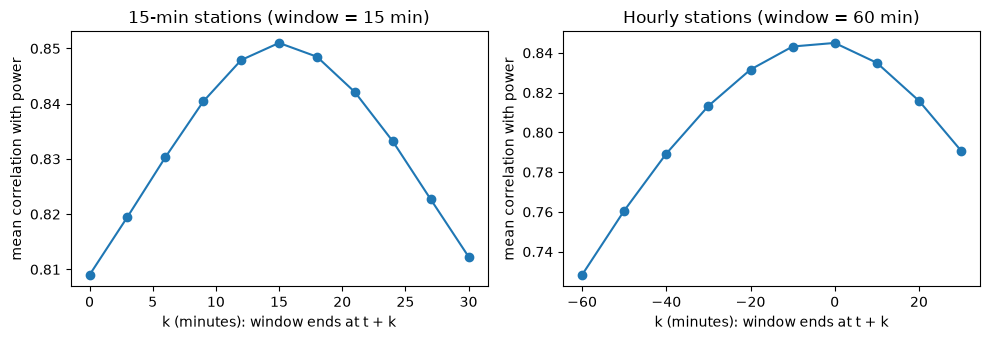

In [28]:
table_15.to_csv('../results/tables/01_timestamp_alignment_15min.csv')
table_60.to_csv('../results/tables/01_timestamp_alignment_hourly.csv')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
table_15['power_W'].plot(ax=axes[0], marker='o')
axes[0].set_title('15-min stations (window = 15 min)')
table_60['power_W'].plot(ax=axes[1], marker='o')
axes[1].set_title('Hourly stations (window = 60 min)')
for ax in axes:
    ax.set_xlabel('k (minutes): window ends at t + k')
    ax.set_ylabel('mean correlation with power')
plt.tight_layout()
plt.savefig('../results/figures/01_timestamp_alignment.png', dpi=120)
plt.show()

### Findings: timestamp convention

- **Grid:** weather timestamps are whole minutes; 15-min power files use :00/:15/:30/:45 and hourly files use :00, so all series sit on the same minute grid (no offsets in seconds).
- **15-min optimizer stations:** the correlation peaks at `k = 12-18` (pooled peak at `k = 15`; the same for 2021, 2022 and 2023, and for both `power(W)` and `generation(kWh)`). A value labelled `t` therefore describes the interval **after** `t`, i.e. `[t, t + 15 min)`: the label is the interval **start**.
- **Hourly stations:** the correlation peaks at `k` between -10 and 0 (22 of 23 stations at -10 or 0). A value labelled `t` describes the hour **before** `t`, i.e. `[t - 60 min, t)`: the label is the interval **end**. So the two station types use **different conventions**.
- **Consequence for leakage (Stage 2):** a 15-min row labelled `t` contains information up to `t + 15 min`, so it is only known at `t + 15 min`. An hourly row labelled `t` is known at `t`. Feature construction and the forecast issue time must use this, otherwise the models see the future.
- **Limits:** the result is relative to the weather timestamps (we assume the 1-min irradiance is labelled at the minute it is measured; an error of about 1 min would not change the result). The correlation peak is broad, so the offset is known to about +-3 min, not exactly. The answer is based on correlation with irradiance, not on a statement in the dataset documentation, which we did not find.

## 5. Missing data and gaps

A value is *missing* if its timestamp is absent from the file or the value is NaN. We look at it on a regular grid (15 min, 1 h or 1 min) between a series' first and last timestamp. Nothing is filled here; filling rules are decided in Stage 2.

For each series: % missing, number of gaps (runs of consecutive missing steps) and the longest gap.

In [29]:
from src import quality

### 5.1 Stations (60)

In [30]:
station_rows = []
station_masks = {}
for name, has_opt, path in zip(files['station'], files['has_optimizer'], files['path']):
    power = data_io.read_station_power(path)['power(W)']
    freq = '15min' if has_opt else '1h'
    mask = quality.missing_mask(power, power.index.min(), power.index.max(), freq)
    stats = quality.gap_stats(mask, freq)
    stats['station'] = name
    stats['has_optimizer'] = has_opt
    station_rows.append(stats)
    station_masks[name] = mask

In [31]:
stations = pd.DataFrame(station_rows)
stations.sort_values('pct_missing', ascending=False).head(10)

,expected_steps,missing_steps,pct_missing,n_gaps,longest_gap_steps,longest_gap_hours,station,has_optimizer
56,19991,2122,10.61,222,10,10.0,UG Hall4 Flexible PV,False
36,55584,2338,4.21,252,44,11.0,Zone L2,True
37,23303,937,4.02,96,10,10.0,CYT (Station 1),False
9,17664,677,3.83,24,44,11.0,SQ Block P,True
49,24299,793,3.26,91,10,10.0,SQ17,False
54,23842,755,3.17,83,10,10.0,SQ9,False
53,23837,739,3.10,80,10,10.0,SQ8,False
35,74784,2193,2.93,74,44,11.0,Zone J2,True
40,9052,258,2.85,29,10,10.0,SQ Block Q (Phrase 2),False
2,90624,2571,2.84,76,44,11.0,LSK South,True


In [32]:
stations.groupby('has_optimizer')['pct_missing'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
has_optimizer,,,,,,,,
False,23.0,2.54,1.89,1.22,1.83,1.93,2.79,10.61
True,37.0,0.80,1.17,0.01,0.03,0.19,1.08,4.21


### 5.2 When is data missing? (hour of day, and whole days)

In [33]:
by_hour = pd.concat([m.groupby(m.index.hour).mean() for m in station_masks.values()], axis=1).mean(axis=1) * 100
by_hour.round(2)

0     0.00
1     0.00
2     0.00
3     0.00
4     0.00
5     0.00
6     0.00
7     1.60
8     3.30
9     3.24
10    3.24
11    3.28
12    3.32
13    3.34
14    3.36
15    3.35
16    3.42
17    3.69
18    0.00
19    0.00
20    0.00
21    0.00
22    0.00
23    0.00
dtype: float64

Missing values occur only between 07:00 and 17:59 (nothing is missing at night: the night zeros are recorded). So the overall % missing is diluted by the night hours. Below we also compute the % missing inside the 07:00-17:59 window and the number of days with any missing value.

In [34]:
window_pct = []
days_missing = []
for name in stations['station']:
    mask = station_masks[name]
    in_window = mask[(mask.index.hour >= 7) & (mask.index.hour <= 17)]
    window_pct.append(round(100 * in_window.mean(), 2))
    days_missing.append(int(mask.groupby(mask.index.date).any().sum()))

stations['pct_missing_0700_1759'] = window_pct
stations['days_with_missing'] = days_missing

In [35]:
stations.sort_values('pct_missing_0700_1759', ascending=False)[['station', 'has_optimizer', 'pct_missing', 'pct_missing_0700_1759', 'days_with_missing', 'n_gaps', 'longest_gap_hours']].head(10)

,station,has_optimizer,pct_missing,pct_missing_0700_1759,days_with_missing,n_gaps,longest_gap_hours
56,UG Hall4 Flexible PV,False,10.61,23.16,222,222,10.0
36,Zone L2,True,4.21,9.18,191,252,11.0
37,CYT (Station 1),False,4.02,8.77,96,96,10.0
9,SQ Block P,True,3.83,8.36,23,24,11.0
49,SQ17,False,3.26,7.12,91,91,10.0
54,SQ9,False,3.17,6.91,83,83,10.0
53,SQ8,False,3.10,6.76,80,80,10.0
35,Zone J2,True,2.93,6.40,67,74,11.0
40,SQ Block Q (Phrase 2),False,2.85,6.22,29,29,10.0
2,LSK South,True,2.84,6.19,76,76,11.0


Typical 15-min gap: 44 steps = 11 h starting at 07:00, i.e. the whole daytime of one day. Check that for the longest gaps:

In [36]:
long_gaps = stations['longest_gap_steps'].value_counts().head(5)
long_gaps

longest_gap_steps
10    23
44    18
2      5
25     2
26     2
Name: count, dtype: int64

Are the missing days shared between stations (a system-wide problem) or specific to one station? For each date: the share of *active* stations (those with data on that date) that have any missing value.

In [37]:
any_missing = {}
for name, mask in station_masks.items():
    any_missing[name] = mask.groupby(mask.index.normalize()).any()
any_missing = pd.DataFrame(any_missing)

share_missing = any_missing.sum(axis=1) / any_missing.notna().sum(axis=1)
print('dates with any missing value:', (share_missing > 0).sum())
print('dates where at least 25 % of active stations are missing:', (share_missing >= 0.25).sum())
share_missing.sort_values(ascending=False).head(8).round(2)

dates with any missing value: 758
dates where at least 25 % of active stations are missing: 67


2021-03-10     1.0
2021-03-15     1.0
2021-04-28     1.0
2021-05-12     1.0
2021-03-11     1.0
2023-09-08     0.7
2022-12-16    0.57
2022-11-22    0.57
dtype: object

### 5.3 Weather variables (1-min, 2021-2023; rainfall 2022-2023)

In [38]:
weather_rows = []
weather_masks = {}
for variable in data_io.WEATHER_VARIABLES:
    table = data_io.read_weather(variable)
    start = '2022-01-01' if variable == 'rainfall' else '2021-01-01'
    for column in table.columns:
        mask = quality.missing_mask(table[column], start, '2023-12-31 23:59', '1min')
        stats = quality.gap_stats(mask, '1min')
        stats['variable'] = column
        weather_rows.append(stats)
        weather_masks[column] = mask

In [39]:
weather = pd.DataFrame(weather_rows)
weather

,expected_steps,missing_steps,pct_missing,n_gaps,longest_gap_steps,longest_gap_hours,variable
0,1576800,9008,0.57,7,5924,98.73,Irradiance (W/m2)
1,1576800,9088,0.58,13,5924,98.73,Temp (Degree Celsius)
2,1576800,9135,0.58,41,5924,98.73,RH (%)
3,1576800,9008,0.57,7,5924,98.73,SLP (hPa)
4,1576800,9008,0.57,7,5924,98.73,Vis (km)
5,1576800,9625,0.61,331,5924,98.73,Wind Speed (m/s)
6,1576800,9625,0.61,331,5924,98.73,Wind Direction (degree)
7,1051200,9006,0.86,5,5924,98.73,Rainfall(mm)


The three longest gaps of irradiance (the other variables share the biggest one):

In [40]:
quality.longest_gaps(weather_masks['Irradiance (W/m2)'], '1min')

,start,steps,hours
0,2023-09-10 06:58:00,5924,98.73
1,2022-12-02 10:21:00,2680,44.67
2,2022-01-19 01:25:00,393,6.55


### 5.4 Save the table and figures

In [41]:
stations_out = stations.rename(columns={'station': 'name'})
stations_out['kind'] = 'station'
weather_out = weather.rename(columns={'variable': 'name'})
weather_out['kind'] = 'weather'
summary = pd.concat([stations_out, weather_out], ignore_index=True)
summary.to_csv('../results/tables/01_missing_summary.csv', index=False)
summary.shape

(68, 11)

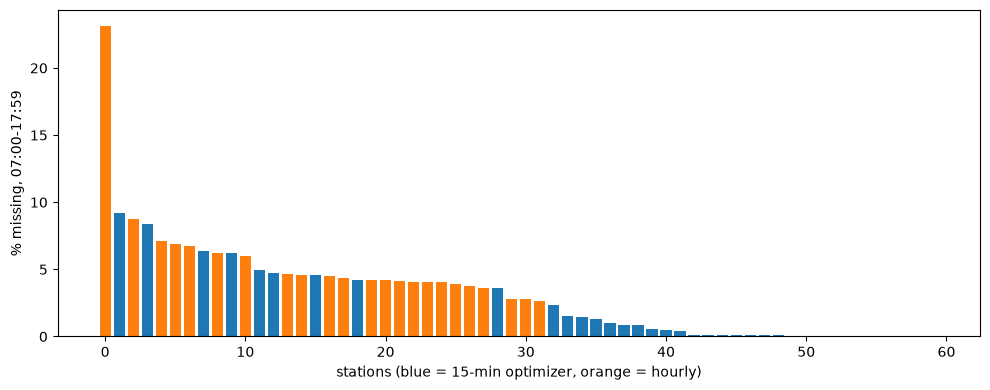

In [42]:
ordered = stations.sort_values('pct_missing_0700_1759', ascending=False)
colors = ordered['has_optimizer'].map({True: 'tab:blue', False: 'tab:orange'})
plt.figure(figsize=(10, 4))
plt.bar(range(len(ordered)), ordered['pct_missing_0700_1759'], color=colors)
plt.xlabel('stations (blue = 15-min optimizer, orange = hourly)')
plt.ylabel('% missing, 07:00-17:59')
plt.tight_layout()
plt.savefig('../results/figures/01_missing_by_station.png', dpi=120)
plt.show()

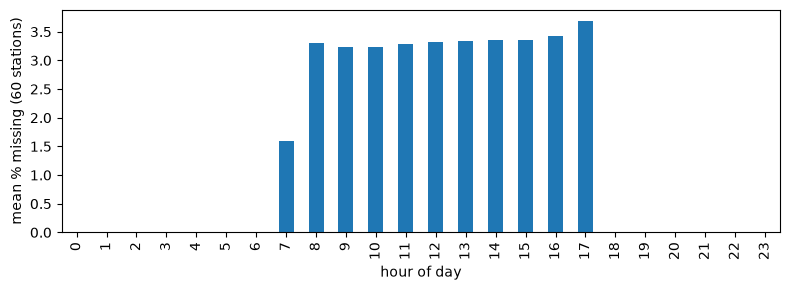

In [43]:
by_hour.plot(kind='bar', figsize=(8, 3))
plt.xlabel('hour of day')
plt.ylabel('mean % missing (60 stations)')
plt.tight_layout()
plt.savefig('../results/figures/01_missing_by_hour.png', dpi=120)
plt.show()

### Findings: missing data

- **Stations:** missing is small for most stations. 15-min optimizer stations: median 0.19 % missing (max 4.2 %); hourly stations: median 1.9 % (max 10.6 %, `UG Hall4 Flexible PV`).
- **Daytime only:** missing values occur only between 07:00 and 17:59; night values are always present (recorded as zero). The overall % is therefore diluted: inside 07:00-17:59 the worst station misses 23 % and the worst optimizer station 9 %.
- **Whole days:** the longest gap of most stations is one daytime period of one day (10 steps for hourly, 44 steps = 11 h for 15-min), and `days_with_missing` is close to `n_gaps`. So the typical failure is a lost day-time, not a short sample dropout. Filling such gaps is not sensible (the plan fills short gaps only; longer gaps are dropped).
- **Mostly station-specific, a few system-wide days:** 758 dates have a missing value somewhere, but only 67 dates have at least 25 % of the active stations missing. The clearest system-wide days are 2021-04-28 (all 11 active stations) and 2021-05-12 (all 12 active stations), and 2023-09-08 (42 of 60 stations, in the test year). The 2021-03 dates with a share of 1.0 have only one active station, so they say little.
- **Weather (1-min):** 0.57-0.86 % of minutes missing. One long gap of 98.7 h starting 2023-09-10 06:58 is shared by all variables, followed by 44.7 h on 2022-12-02 and 6.6 h on 2022-01-19 (irradiance). The September 2023 gap lies in the 2023 test year: features that use irradiance cannot be built for those 4 days, so this must be handled explicitly in Stage 2 (exclude those targets; no filling).
- Wind and humidity have many more short gaps (331 and 41) than the other variables (7).
- Missing values are not the same as the duplicated timestamps found earlier (4 files); those are handled in Stage 2.

## 6. Outliers

Physical bounds from `PLAN.md` §5: power must be >= 0 and <= 1.2 x rated power; irradiance <= 1500 W/m2. Here we only **flag and count**. Nothing is changed or removed (that is Stage 2).

### 6.1 Power per station

In [44]:
from src import data_io
files = data_io.list_station_files().set_index('station')

In [45]:
rows = []
for _, s in inv.iterrows():
    power = data_io.read_station_power(files.loc[s['station'], 'path'])['power(W)']
    rated_w = s['rated_value'] * 1000
    rows.append({
        'station': s['station'],
        'has_optimizer': s['has_optimizer'],
        'rated_W': rated_w,
        'min_W': power.min(),
        'max_W': power.max(),
        'max_over_rated': round(power.max() / rated_w, 2),
        'n_negative': int((power < 0).sum()),
        'n_above_1.0_rated': int((power > rated_w).sum()),
        'n_above_1.2_rated': int((power > 1.2 * rated_w).sum()),
    })
outliers = pd.DataFrame(rows)

In [46]:
print('stations with negative power:', (outliers['n_negative'] > 0).sum())
print('stations above 1.2 x rated:', (outliers['n_above_1.2_rated'] > 0).sum())
print('stations above 1.0 x rated:', (outliers['n_above_1.0_rated'] > 0).sum())

stations with negative power: 9
stations above 1.2 x rated: 5
stations above 1.0 x rated: 20


In [47]:
outliers.sort_values('max_over_rated', ascending=False).head(8)

,station,has_optimizer,rated_W,min_W,max_W,max_over_rated,n_negative,n_above_1.0_rated,n_above_1.2_rated
55,Tower A,False,40290.0,-8676419.0,3.175512e+07,788.16,1,2,2
54,SQ9,False,30810.0,-303000.0,1.293365e+06,41.98,1,1,1
56,UG Hall4 Flexible PV,False,19840.0,-19756.0,1.778270e+05,8.96,1,2,2
39,SQ Apartment37-48 Flexible PV,False,3720.0,0.0,7.179000e+03,1.93,0,146,116
33,Zone D,True,68620.0,0.0,8.341719e+04,1.22,0,307,5
19,UG Hall2 RF,True,8000.0,0.0,8.475000e+03,1.06,0,380,0
36,Zone L2,True,10000.0,0.0,1.047213e+04,1.05,0,9,0
7,SQ Apartment25-36,True,17000.0,0.0,1.721833e+04,1.01,0,205,0


The negative values and the huge maxima: are they isolated single steps? Look at one example (`Tower A`, which has the ~31 MW value).

In [48]:
tower = data_io.read_station_power(files.loc['Tower A', 'path'])
t = tower['power(W)'].idxmax()
tower.loc[t - pd.Timedelta('2h'):t + pd.Timedelta('2h')]

,generation(kWh),power(W)
Time,,
2022-04-23 01:00:00,0.000,0.0
2022-04-23 02:00:00,0.000,0.0
2022-04-23 03:00:00,31755.125,31755125.0
2022-04-23 04:00:00,0.000,0.0
2022-04-23 05:00:00,0.000,0.0


In [49]:
sq12 = data_io.read_station_power(files.loc['SQ12', 'path'])
t = sq12['power(W)'].idxmin()
sq12.loc[t - pd.Timedelta('2h'):t + pd.Timedelta('2h')]

,generation(kWh),power(W)
Time,,
2021-09-05 06:00:00,0.000,0.0
2021-09-05 07:00:00,0.329,329.0
2021-09-05 08:00:00,-1788.727,-1788727.0
2021-09-05 09:00:00,6.311,6311.0
2021-09-05 10:00:00,11.659,11659.0


Both look like one-step glitches (a kWh-sized value in a single hour, with normal values next to it).

`SQ Apartment37-48 Flexible PV` is different: 116 values above 1.2 x rated. When do they happen?

In [50]:
flex = data_io.read_station_power(files.loc['SQ Apartment37-48 Flexible PV', 'path'])['power(W)']
too_high = flex[flex > 1.2 * 3720]
too_high.index.to_period('M').value_counts().sort_index()

Time
2023-11    47
2023-12    69
Freq: M, Name: count, dtype: int64

### 6.2 Irradiance above 1500 W/m2

In [51]:
irr = data_io.read_weather('irradiance')['Irradiance (W/m2)']
high = irr[irr > 1500]
print('values above 1500:', len(high), 'of', irr.notna().sum())

values above 1500: 739 of 1567792


In [52]:
print(high.index.hour.value_counts().sort_index())
print(high.index.to_period('M').value_counts().sort_index())

Time
9       7
10     35
11    236
12    310
13    138
14     13
Name: count, dtype: int64
Time
2023-02     11
2023-04      1
2023-05     65
2023-06    233
2023-07    219
2023-08    202
2023-09      6
2023-10      2
Freq: M, Name: count, dtype: int64


In [53]:
for limit in [1400, 1500, 1600, 2000, 3000]:
    print('above', limit, ':', (irr > limit).sum())

above 1400 : 2189
above 1500 : 739
above 1600 : 182
above 2000 : 5
above 3000 : 1


### 6.3 Save the table

In [54]:
outliers.to_csv('../results/tables/01_outlier_summary.csv', index=False)
outliers.shape

(60, 9)

### Findings: outliers

- **Negative power:** 9 stations, all hourly (non-optimizer). Each has only 1-2 negative values, but they are huge (down to -8.7 MW), e.g. `Tower A` 2022-04-24 21:00 and `SQ12` 2021-09-05 08:00. They are single-step glitches with normal values around them.
- **Huge positive spikes:** `Tower A` (31.8 MW, 2022-04-23 03:00, at night), `SQ9` (1.3 MW) and `UG Hall4 Flexible PV` (178 kW) are also single-step glitches. They are far above 1.2 x rated, so a rule using the rated power catches them. These stations have a few values each; the optimizer stations have no negative values.
- **Above 1.2 x rated, not a glitch:** `SQ Apartment37-48 Flexible PV` has 116 values up to 1.93 x rated, **all in 2023-11 and 2023-12** (rated 3.72 kW). This looks like a capacity change or a wrong rated value, not a glitch (*cause unverified*). `Zone D` has 5 values (max 1.22 x rated). Other stations exceed 1.0 x rated slightly (e.g. `Zone D` 307, `UG Hall2 RF` 380 steps, max 1.06), which is normal when the rated power is a nameplate value.
- **Irradiance above 1500 W/m2:** 739 values (0.05 %), all between 09:00 and 14:59, mostly May-August around noon. 557 of them are below 1600, so most are plausible short peaks (cloud enhancement), not errors. Only 5 values are above 2000 and 1 above 3000 (max 3608.6); these are sensor errors.
- **Decision for Stage 2 (to be applied there):** power outside [0, 1.2 x rated] is set to missing (not clipped), because the glitches are far outside the range and clipping would invent a value. Irradiance above 2000 W/m2 is set to missing; values between 1500 and 2000 are kept and flagged. Check `SQ Apartment37-48 Flexible PV` (2023 only; it is in the test year) before deciding. The plan's limit of 1500 W/m2 is revised to 2000 (see Change log).

## 7. Day/night and seasonal profiles

To compare stations, power is divided by rated power (a *normalised* value, about 0 to 1). Values outside [0, 1.2 x rated] are set to missing first (the glitches from section 6). Hourly stations are labelled at the interval end, so one hour is subtracted to put every station on the interval **start** label.

### 7.1 Build one normalised series per station

In [55]:
series = {}
for _, s in inv.iterrows():
    power = data_io.read_station_power(files.loc[s['station'], 'path'])['power(W)']
    power = power[~power.index.duplicated()].sort_index()
    rated_w = s['rated_value'] * 1000
    power = power.where((power >= 0) & (power <= 1.2 * rated_w))
    if not s['has_optimizer']:
        power.index = power.index - pd.Timedelta('1h')
    series[s['station']] = power / rated_w
len(series)

60

### 7.2 Day/night pattern

How much power is recorded at night (hours 22:00-03:59) and what is the first and last hour with real output?

In [56]:
night_rows = []
for name, x in series.items():
    hour = x.index.hour
    night = x[(hour >= 22) | (hour < 4)].dropna()
    by_hour = x.groupby(hour).mean()
    daylight = by_hour[by_hour > 0.02]
    night_rows.append({
        'station': name,
        'night_share_nonzero': round((night > 0).mean(), 4),
        'night_max': round(night.max(), 3),
        'first_hour': daylight.index.min(),
        'last_hour': daylight.index.max(),
    })
night_table = pd.DataFrame(night_rows)
night_table.describe()

,night_share_nonzero,night_max,first_hour,last_hour
count,60.000000,60.000000,60.000000,60.000000
mean,0.000010,0.009800,7.016667,16.966667
std,0.000044,0.048815,0.129099,0.181020
min,0.000000,0.000000,7.000000,16.000000
25%,0.000000,0.000000,7.000000,17.000000
50%,0.000000,0.000000,7.000000,17.000000
75%,0.000000,0.000000,7.000000,17.000000
max,0.000200,0.269000,8.000000,17.000000


In [57]:
night_table.sort_values('night_share_nonzero', ascending=False).head(8)

,station,night_share_nonzero,night_max,first_hour,last_hour
45,SQ13,0.0002,0.052,7,17
39,SQ Apartment37-48 Flexible PV,0.0002,0.269,7,17
47,SQ15,0.0002,0.267,7,17
44,SQ12,0.0000,0.000,7,17
32,Zone A7,0.0000,0.000,7,17
33,Zone D,0.0000,0.000,7,17
34,Zone J1,0.0000,0.000,7,17
35,Zone J2,0.0000,0.000,7,17


Mean normalised power by hour of day, one line per station (blue = 15-min optimizer, orange = hourly):

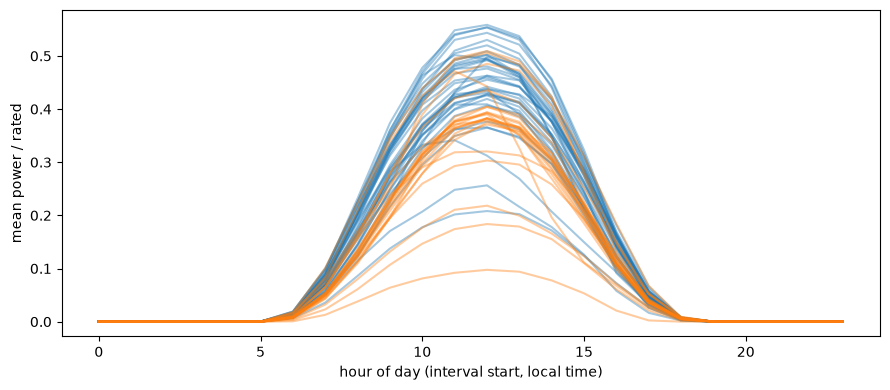

In [58]:
plt.figure(figsize=(9, 4))
for name, x in series.items():
    colour = 'tab:blue' if inv.set_index('station').loc[name, 'has_optimizer'] else 'tab:orange'
    x.groupby(x.index.hour).mean().plot(color=colour, alpha=0.4)
plt.xlabel('hour of day (interval start, local time)')
plt.ylabel('mean power / rated')
plt.tight_layout()
plt.savefig('../results/figures/01_hourly_profile.png', dpi=120)
plt.show()

### 7.3 Seasonal pattern

Mean normalised power over daytime hours (08:00-16:59) for each calendar month, averaged over stations of the same type. Only stations with data in that month count.

In [59]:
monthly = {}
for name, x in series.items():
    day = x[(x.index.hour >= 8) & (x.index.hour < 17)]
    monthly[name] = day.groupby(day.index.month).mean()
monthly = pd.DataFrame(monthly)
monthly.round(2).iloc[:, :6]

,Indoor Sports Centre,LSK North,LSK South,Library,S H Ho Sports Hall,SQ Apartment1-12
Time,,,,,,
1,0.19,0.29,0.28,0.21,0.14,0.32
2,0.30,0.32,0.31,0.27,0.17,0.35
3,0.39,0.35,0.34,0.25,0.21,0.38
4,0.42,0.38,0.36,0.22,0.28,0.39
5,0.39,0.35,0.34,0.28,0.29,0.36
6,0.43,0.39,0.38,0.31,0.34,0.40
7,0.56,0.49,0.48,0.41,0.44,0.52
8,0.49,0.43,0.43,0.34,0.35,0.44
9,0.30,0.46,0.50,0.28,0.28,0.49


In [60]:
has_opt = inv.set_index('station')['has_optimizer']
by_type = monthly.T.groupby(has_opt).mean().T
by_type.columns = ['hourly (no optimizer)', '15-min (optimizer)']
by_type.round(3)

,hourly (no optimizer),15-min (optimizer)
Time,,
1,0.200,0.246
2,0.225,0.283
3,0.240,0.301
4,0.248,0.316
5,0.260,0.302
6,0.251,0.340
7,0.328,0.439
8,0.287,0.373
9,0.305,0.374


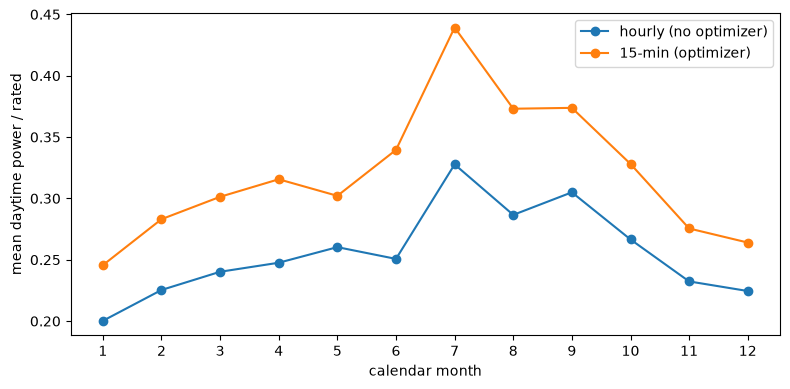

In [61]:
by_type.plot(marker='o', figsize=(8, 4))
plt.xlabel('calendar month')
plt.ylabel('mean daytime power / rated')
plt.xticks(range(1, 13))
plt.tight_layout()
plt.savefig('../results/figures/01_seasonal_profile.png', dpi=120)
plt.show()

### 7.4 Is every season in the training period?

The plan trains on data up to 2022-09-30. Count the daytime rows per season in that period (seasons: Dec-Feb, Mar-May, Jun-Aug, Sep-Nov) and the number of stations that have data.

In [62]:
season_of_month = {12: 'winter', 1: 'winter', 2: 'winter', 3: 'spring', 4: 'spring', 5: 'spring',
                   6: 'summer', 7: 'summer', 8: 'summer', 9: 'autumn', 10: 'autumn', 11: 'autumn'}
train_rows = []
for name, x in series.items():
    x = x.dropna()[:'2022-09-30']
    counts = x.groupby(x.index.month.map(season_of_month)).size()
    for season, n in counts.items():
        train_rows.append({'station': name, 'season': season, 'rows': n})
train_table = pd.DataFrame(train_rows)
train_table.groupby('season').agg(stations=('station', 'nunique'), rows=('rows', 'sum'))

,stations,rows
season,,
autumn,54,340331
spring,51,333117
summer,54,494791
winter,49,293910


In [63]:
per_station = train_table.pivot(index='station', columns='season', values='rows').fillna(0)
print('stations with no training data in a season:')
(per_station == 0).sum()

stations with no training data in a season:


season
autumn    0
spring    3
summer    0
winter    5
dtype: int64

In [64]:
by_year_month = pd.concat([x.dropna().groupby([x.dropna().index.year, x.dropna().index.month]).size() for x in series.values()], axis=1).notna().sum(axis=1)
by_year_month.unstack(0).fillna(0).astype(int)

Time,2021,2022,2023,2024
Time,,,,
1,0,49,56,1
2,0,49,57,0
3,6,51,58,0
4,11,51,58,0
5,13,51,58,0
6,23,54,58,0
7,31,54,59,0
8,36,54,60,0
9,39,54,60,0


The last table shows how many stations have data in each month of each year.

### Findings: day/night and seasonal profiles

- **Night:** after removing the glitches, night values (22:00-03:59) are zero almost everywhere: the share of non-zero night values is at most 0.02 % per station (median 0). The largest night value is 0.27 x rated (`SQ15`, `SQ Apartment37-48 Flexible PV`); these are rare. Setting night to 0 using sun elevation in Stage 2 is safe.
- **Daylight window:** on the interval-start label, every station has output from hour 07 to hour 16 (first hour 7 for 59 stations, 8 for one; last hour 16 or 17). The hourly profile curves of both station types line up after the 1-hour shift, which supports the timestamp convention from section 4.
- **Seasonal pattern:** the mean daytime power / rated is highest in July (0.44 optimizer, 0.33 hourly) and lowest in November-December (about 0.26 and 0.22). It is higher in spring and summer than in winter. Optimizer stations have higher values than hourly ones in every month (both are normalised by rated power).
- **Season coverage in training (up to 2022-09-30):** all four seasons are present (stations with data: autumn 54, spring 51, summer 54, winter 49). 3 stations have no spring and 5 have no winter data in training; they are the stations that start late (this matters for the unseen-station split in Stage 2). Winter has the fewest rows (about 294 k vs 495 k for summer).
- **Station growth:** only 6 stations have data in March 2021, 48 in December 2021 and 56-60 in 2023. Almost all of the 2021 training data comes from the second half of the year. One station (`Zone L1 (Station 1)`) has a single month in 2024-01.
- **Not checked:** the seasonal values include all weather conditions; a cloudier summer or sparser sampling in one month could change the picture a little. No test is made here.

## 8. Power vs irradiance per station type

The campus has one irradiance sensor, so this shows how well one sensor explains each station. Irradiance (1-min) is averaged over the same interval as the power value. Because `series` (section 7) already uses the interval-**start** label for every station, a plain `resample` (left label) matches. Irradiance above 2000 W/m2 is set to missing (section 6). An average needs at least 80 % of the minutes.

### 8.1 Irradiance on the 15-min and hourly grids

In [65]:
irr_clean = irr.where(irr <= 2000)
irr_15 = irr_clean.resample('15min').mean()
irr_15[irr_clean.resample('15min').count() < 12] = float('nan')
irr_60 = irr_clean.resample('60min').mean()
irr_60[irr_clean.resample('60min').count() < 48] = float('nan')
irr_15.notna().sum(), irr_60.notna().sum()

(np.int64(104517), np.int64(26129))

### 8.2 One table per station: correlation and a simple ratio

Only daytime rows with irradiance above 20 W/m2 are used. The ratio is normalised power divided by irradiance in kW/m2, taken for rows with irradiance of at least 400 W/m2 (a rough 'performance' number).

In [66]:
stat_rows = []
samples = []
for name, x in series.items():
    is_opt = bool(has_opt[name])
    irr_grid = irr_15 if is_opt else irr_60
    both = pd.concat([x.rename('power'), irr_grid.rename('irr')], axis=1, join='inner').dropna()
    both = both[both['irr'] > 20]
    high = both[both['irr'] >= 400]
    stat_rows.append({
        'station': name,
        'has_optimizer': is_opt,
        'n_rows': len(both),
        'corr': round(both['power'].corr(both['irr']), 3),
        'median_ratio_high_irr': round((high['power'] / (high['irr'] / 1000)).median(), 3),
    })
    samples.append(both.sample(min(1500, len(both)), random_state=42).assign(has_optimizer=is_opt))
pv_irr = pd.DataFrame(stat_rows)
samples = pd.concat(samples)
pv_irr.groupby('has_optimizer')[['corr', 'median_ratio_high_irr']].describe().T

has_optimizer                    False      True 
corr                  count  23.000000  37.000000
                      mean    0.885609   0.897027
                      std     0.107949   0.039584
                      min     0.473000   0.798000
                      25%     0.908000   0.886000
                      50%     0.917000   0.898000
                      75%     0.929000   0.912000
                      max     0.949000   0.978000
median_ratio_high_irr count  23.000000  37.000000
                      mean    0.615826   0.768189
                      std     0.200570   0.165704
                      min     0.000000   0.339000
                      25%     0.571000   0.678000
                      50%     0.644000   0.753000
                      75%     0.679500   0.868000
                      max     0.965000   1.069000

In [67]:
pv_irr.sort_values('corr').head(8)

,station,has_optimizer,n_rows,corr,median_ratio_high_irr
56,UG Hall4 Flexible PV,False,9747,0.473,0.000
52,SQ567 Flexible PV,False,11571,0.651,0.376
35,Zone J2,True,42544,0.798,0.696
4,S H Ho Sports Hall,True,43509,0.806,0.559
18,UG Hall2 2F,True,50122,0.834,0.413
27,Zone A1,True,50635,0.851,0.801
0,Indoor Sports Centre,True,43787,0.852,0.806
37,CYT (Station 1),False,12517,0.852,0.702


### 8.3 Scatter plot (1500 random rows per station)

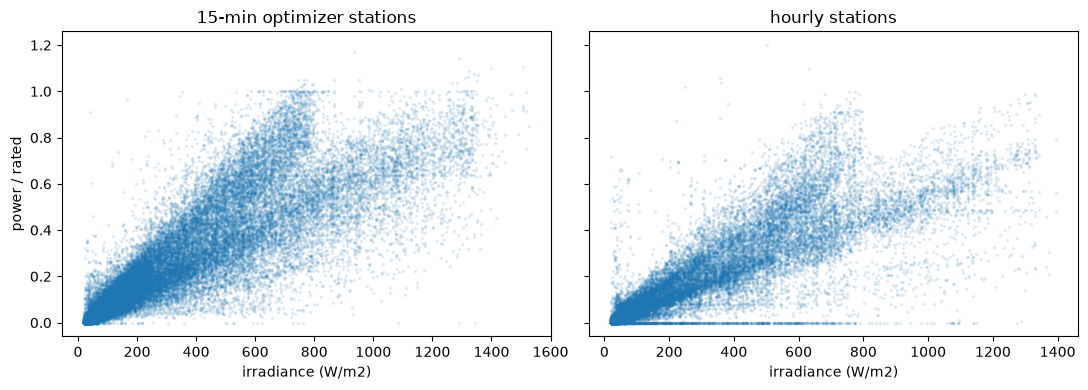

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (is_opt, label) in zip(axes, [(True, '15-min optimizer stations'), (False, 'hourly stations')]):
    part = samples[samples['has_optimizer'] == is_opt]
    ax.scatter(part['irr'], part['power'], s=2, alpha=0.1)
    ax.set_title(label)
    ax.set_xlabel('irradiance (W/m2)')
axes[0].set_ylabel('power / rated')
plt.tight_layout()
plt.savefig('../results/figures/01_power_vs_irradiance.png', dpi=120)
plt.show()

Median normalised power in bins of irradiance (one line per station type):

In [69]:
samples['irr_bin'] = (samples['irr'] // 100) * 100
bins = samples.groupby(['irr_bin', 'has_optimizer'])['power'].median().unstack()
bins.columns = ['hourly (no optimizer)', '15-min (optimizer)']
bins.round(3)

,hourly (no optimizer),15-min (optimizer)
irr_bin,,
0.0,0.000,0.000
100.0,0.089,0.110
200.0,0.162,0.199
300.0,0.228,0.276
400.0,0.285,0.372
500.0,0.399,0.457
600.0,0.454,0.557
700.0,0.472,0.589
800.0,0.468,0.554


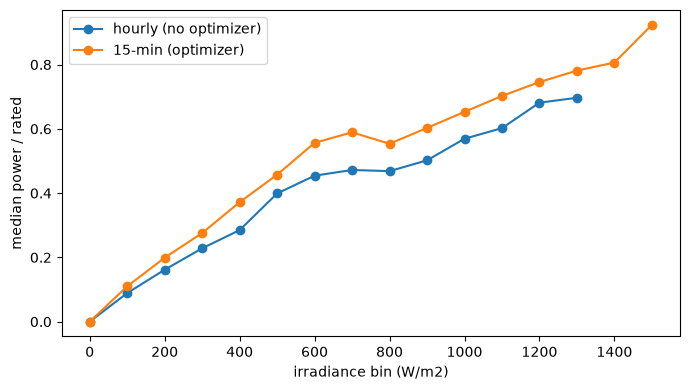

In [70]:
bins.plot(marker='o', figsize=(7, 4))
plt.xlabel('irradiance bin (W/m2)')
plt.ylabel('median power / rated')
plt.tight_layout()
plt.savefig('../results/figures/01_power_vs_irradiance_bins.png', dpi=120)
plt.show()

### 8.4 Save the table

In [71]:
pv_irr.to_csv('../results/tables/01_power_vs_irradiance.csv', index=False)
pv_irr.shape

(60, 5)

### Findings: power vs irradiance

- **One campus sensor explains most of the power:** daytime correlation (irradiance > 20 W/m2) is median 0.90 for the 37 optimizer stations (min 0.80, max 0.98) and median 0.92 for the 23 hourly stations (min 0.47). The hourly stations are higher at the median but have a long tail.
- **Weak stations:** `UG Hall4 Flexible PV` (corr 0.47, median ratio 0.0, i.e. at least half of its high-irradiance rows are zero) and `SQ567 Flexible PV` (0.65). Among optimizer stations, `Zone J2`, `S H Ho Sports Hall` and `UG Hall2 2F` are lowest (0.80-0.83). These are candidates for the station-set gate and the unseen-station split. Cause (shading, orientation, outages) not checked.
- **Shape:** power is close to linear in irradiance up to about 700 W/m2, then a second, lower cloud appears at 800-1400 W/m2 (the scatter plot). The binned medians flatten between 600 and 900 W/m2 (e.g. optimizer 0.56 at 600 and 0.55 at 800, then rising again). A likely reason is that high irradiance happens when the sun is high, and tilted panels receive less of it, but this is a hypothesis; the sensor type (horizontal or tilted) is not stated. It means irradiance alone is not enough: solar geometry and station tilt/azimuth are needed as features.
- **Clipping:** optimizer stations show a flat line at 1.0 x rated (inverter limit), and some points reach 1.05-1.1.
- **Zero-output rows:** hourly stations show a horizontal line at zero power even with irradiance up to 1300 W/m2: these are outages or faulty readings. They matter for Stage 8 (fault flagging) and for training (a model could learn to predict zero). Count them in Stage 2.
- **Performance ratio (power / rated divided by irradiance in kW/m2, at irradiance >= 400):** median 0.75 for optimizer and 0.64 for hourly stations. These are rough numbers; they depend on the unknown sensor orientation and on temperature.

## 9. Station-set gate

`PLAN.md` assumes: 15-min horizon = the 37 optimizer stations (15-min data); 1-h and day-ahead = all 60 stations. This section checks that with the data. Nothing is decided about the unseen stations here (that is Stage 2); we only count what is available.

Rules used (simple, and stated so they can be defended):
- **Resolution:** a horizon can only use stations whose native step is the horizon step or finer. Optimizer stations (15 min) can be averaged to hourly; hourly stations cannot be used for 15 min.
- **Coverage:** a split counts a station if it has observed (not missing, not a glitch) daytime values (hours 07-16) on enough days. Thresholds: train at least 180 days, validation at least 45 days, test at least 180 days. Splits: train up to 2022-09-30, validation 2022-10-01 to 2022-12-31, test 2023.

### 9.1 Days with observed daytime values per split

In [72]:
split_edges = {
    'train': ('2021-01-01', '2022-09-30'),
    'val': ('2022-10-01', '2022-12-31'),
    'test': ('2023-01-01', '2023-12-31'),
}
gate_rows = []
for name, x in series.items():
    day = x[(x.index.hour >= 7) & (x.index.hour < 17)].dropna()
    dates = pd.Series(day.index.normalize().unique())
    row = {'station': name, 'has_optimizer': bool(has_opt[name])}
    for split, (a, b) in split_edges.items():
        row['days_' + split] = int(((dates >= a) & (dates <= b)).sum())
    gate_rows.append(row)
gate = pd.DataFrame(gate_rows)
gate.describe()

,days_train,days_val,days_test
count,60.000000,60.000000,60.000000
mean,369.733333,81.883333,343.516667
std,164.331091,26.372232,41.884220
min,0.000000,0.000000,149.000000
25%,326.500000,90.000000,342.000000
50%,446.000000,92.000000,352.500000
75%,487.000000,92.000000,365.000000
max,559.000000,92.000000,365.000000


### 9.2 Classify each station

In [73]:
gate['in_train'] = gate['days_train'] >= 180
gate['in_val'] = gate['days_val'] >= 45
gate['in_test'] = gate['days_test'] >= 180
gate['group'] = 'other'
gate.loc[gate['in_train'] & gate['in_val'] & gate['in_test'], 'group'] = 'seen (train, val, test)'
gate.loc[~gate['in_train'] & gate['in_test'], 'group'] = 'test only (little or no train data)'
gate.groupby(['has_optimizer', 'group']).size()

has_optimizer  group                              
False          seen (train, val, test)                20
               test only (little or no train data)     3
True           other                                   2
               seen (train, val, test)                31
               test only (little or no train data)     4
dtype: int64

Stations that are not in the 'seen' group, with their day counts:

In [74]:
gate[gate['group'] != 'seen (train, val, test)'][['station', 'has_optimizer', 'days_train', 'days_val', 'days_test', 'group']]

,station,has_optimizer,days_train,days_val,days_test,group
3,Library,True,122,88,365,test only (little or no train data)
9,SQ Block P,True,0,0,170,other
17,Shaw Auditorium,True,0,0,149,other
24,UG Hall8,True,0,0,304,test only (little or no train data)
25,UG Hall9,True,0,0,323,test only (little or no train data)
36,Zone L2,True,113,92,365,test only (little or no train data)
40,SQ Block Q (Phrase 2),False,0,12,342,test only (little or no train data)
41,SQ Block Q,False,0,12,342,test only (little or no train data)
50,SQ18,False,99,90,342,test only (little or no train data)


### 9.3 Station sets per horizon

In [75]:
sets = pd.DataFrame({
    '15 min': [gate[gate['has_optimizer']].shape[0], gate[gate['has_optimizer'] & (gate['group'] == 'seen (train, val, test)')].shape[0]],
    '1 h and day-ahead': [gate.shape[0], gate[gate['group'] == 'seen (train, val, test)'].shape[0]],
}, index=['stations with the resolution', 'of them seen (train, val, test)'])
sets

,15 min,1 h and day-ahead
stations with the resolution,37,60
"of them seen (train, val, test)",31,51


In [76]:
gate.to_csv('../results/tables/01_station_sets.csv', index=False)
gate.shape

(60, 9)

### Findings: station-set gate

- **Resolution (as planned):** 37 optimizer stations support 15 min; all 60 support 1 h and day-ahead (the 37 are averaged to hourly). Hourly stations are never used for 15 min.
- **Coverage (differs from the plan's "37 / 60"):** only **31 of the 37** optimizer stations and **51 of the 60** stations are seen in train, validation and test with the thresholds above (180 / 45 / 180 days).
- **Optimizer stations not seen (6):** `SQ Block P` (170 test days, no train) and `Shaw Auditorium` (149 test days, no train) start in 2023 and fall just under the 180-day test threshold; `UG Hall8` and `UG Hall9` start in 2023 (304 and 323 test days); `Library` and `Zone L2` have only 122 and 113 training days (88 and 92 validation days, full test year).
- **Hourly stations not seen (3 of 23):** `SQ Block Q` and `SQ Block Q (Phrase 2)` have no train data and 12 validation days; `SQ18` has 99 training days. All three have 342 test days. `SQ Block Q` and its Phase 2 file have identical day counts; whether they are the same site is *unverified*.
- **Use in Stage 2:** the stations with no (or too little) training data are the natural unseen-station set. Together with the ~6 stations drawn at random from the seen ones, this leaves about 25 of the 31 seen optimizer stations (15 min) and about 45 of the 51 seen stations (1 h and day-ahead) for training. Thresholds are a choice, not a rule from the data; the two stations just under 180 test days (`SQ Block P`, `Shaw Auditorium`) can be revisited.
- **Not included here:** the 98.7 h weather gap in 2023-09 and the zero-output rows of section 8 reduce the usable test rows a little; Stage 2 handles them.

## 10. Stage 1 summary and preprocessing to-do list

### 10.1 What is wrong with the raw data, and how we know

| Issue | Evidence | Section |
|---|---|---|
| Two timestamp styles (ISO and slash) | 84 files ISO, 20 files slash; each file uniform | 2 (loader) |
| Different interval labels | 15-min stations: interval **start**; hourly: interval **end** (inferred by correlation with 1-min irradiance, about +-3 min) | 4 |
| Duplicate timestamps and unsorted rows | 4 site files with duplicates (432, 586, 10099, 2074 rows); `SQ14` also unsorted | 2 |
| Missing data | 15-min stations median 0.19 % missing, hourly median 1.9 %; only 07:00-17:59 is missing; mostly whole lost days | 5 |
| System-wide gaps | 2021-04-28, 2021-05-12, 2023-09-08; weather gap of 98.7 h from 2023-09-10 (in the test year) | 5 |
| Glitch values in power | 9 hourly stations with 1-2 huge negative values; spikes up to 31.8 MW (`Tower A`) | 6 |
| Power above rated | `SQ Apartment37-48 Flexible PV`: 116 values up to 1.93 x rated, all in 2023-11/12 | 6 |
| Irradiance outliers | 739 values above 1500 W/m2 (most are plausible noon peaks); 5 above 2000; max 3608.6 | 6 |
| Zero output at high irradiance (hourly stations) | horizontal line at zero in the scatter plot; `UG Hall4 Flexible PV` corr 0.47 | 8 |
| Energy and power disagree for 15-min stations | summed kWh is 2.8-3.3 % above W x 0.25 h | 3 |
| One weather source, no per-station weather | one campus sensor; corr with power about 0.90 | 8 |
| Stations start at different times | 6 stations in 2021-03, 48 in 2021-12, 56-60 in 2023; winter is the thinnest season in training | 7, 9 |

Good news: timezone is local Hong Kong time (UTC+8), units are W and W/m2, night values are zero almost everywhere, and the daylight window is hours 07-16 (start label).

### 10.2 Preprocessing to-do list for Stage 2

**Loading and timestamps**
1. Drop duplicate timestamps and sort by time (`SQ14`). First check whether duplicate rows have identical values (not checked yet); the rule must be documented.
2. Put all stations on the interval-**start** label (hourly stations: minus 1 h) before joining with weather. A 15-min row labelled `t` is known only at `t + 15 min`; hourly rows are known at their end label. Features and the forecast issue time must respect this.
3. Truncate `Zone L1 (Station 1)` at 2023-12-31 (it runs to 2024-01-01 03:00).

**Cleaning**
4. Power outside [0, 1.2 x rated] becomes missing (not clipped).
5. Irradiance above 2000 W/m2 becomes missing; values between 1500 and 2000 are kept with a flag.
6. Decide what to do with `SQ Apartment37-48 Flexible PV` in 2023-11/12 (a capacity change or a wrong rated value, *unverified*).
7. Count zero-output rows at high irradiance for the hourly stations; decide whether to exclude them from training and how to flag them (they matter for Stage 8). Check `UG Hall4 Flexible PV` and `SQ567 Flexible PV` first.
8. Reindex to a regular grid per station. Fill only short gaps (causal, features only), keep the `is_filled` mask, never evaluate on filled targets. The long lost-day gaps are not filled.
9. Exclude targets that fall in the 2023-09-10 weather gap (98.7 h) and mark the system-wide days (2021-04-28, 2021-05-12, 2023-09-08).

**Resampling and units**
10. Weather from 1 min to 15 min and 60 min means; require at least 80 % of the minutes (as in section 8).
11. Average 15-min optimizer stations to hourly for the 1-h and day-ahead horizons.
12. Use `power(W)` as the target; decide and document how to treat the 2.8-3.3 % difference to the kWh column for 15-min stations.
13. Rainfall exists for 2022-2023 only (`Rainfall_2021.xlsx` not loaded): drop it as a feature or load it, and decide.

**Normalisation and features**
14. Normalise power by rated power from the `.ttl`; any fallback (99th percentile) is computed on train only.
15. Write a parsing rule for tilt and azimuth (`Mixed`, two values such as `0/15deg`).
16. Set night to 0 using sun elevation (daytime: elevation > 5 degrees); add solar geometry and a clear-sky index (pvlib), because irradiance alone does not explain power at high irradiance (section 8).
17. Optimizer stations clip at about 1.0 x rated; keep this in mind when comparing models near the top.

**Splits and station sets**
18. Station sets from section 9: 15 min = 37 with the resolution, 31 seen; 1 h and day-ahead = 60, 51 seen. The 9 stations with little or no training data are the first unseen stations; add about 6 random hold-outs (seed 42).
19. Check that each season is in training (all four are; winter is thinnest) and note that validation is a single season (Q4 2022).
20. Install `pvlib` and `pyarrow` and add them to `requirements.txt`.

### 10.3 Limits of this audit
- The interval convention is inferred from correlation, not stated by the dataset.
- Thresholds in the station-set gate (180 / 45 / 180 days) are a choice.
- The causes of the weak stations, the 2023 over-rated values and the zero-output rows are not investigated.
